```
r_0 = 1 : 첫 번째 행동 후 받은 보상
r_1 = 1 : 두 번째 행동 후 받은 보상
r_2 = 1 : 세 번째 행동 후 받은 보상
γ = 0.9 : 미래 보상에 적용하는 할일율
V(s_3) = 5 : 세 번째 행동 후 상태에서 앞으로 받을 것으로 예상되는 보상
V(s_0) = 4 : 처음 상태에서 앞으로 받을 것으로 예상되는 보상
```
문제
1. AI가 3번의 행동으로 실제 받은 보상의 합계는 얼마?
    - 1+1+1 = 3
2. 미래 보상에 할인율을 적용하여 계산한 3-step Return은 얼마?
$$
    G_0^{(3)}=1+0.9(1)+0.9^2(1)+0.9^3(5)=6.355
$$
    - 실제로 받은 보상은 3점이지만, 3번 행동한 이후의 미래 예상 가치까지 포함하고 할인율을 적용했기 때문에 6.355가 나옴
3. 처음 예상했던 가치와 비교한 Advantage는 얼마?
    - Advantage는 처음 예상했던 가치와 새롭게 계산한 목표 가치의 차이
        - Critic은 현재 상태의 가치를 4점이라고 예상
        - 3번 행동한 경험과 미래 예상 가치를 이용해 계산한 값은 6.355
        - 6.355 - 4 = 2.355
4. 위 결과처럼 Advantage가 양수라는 것은 어떤 의미?
    - 처음 예상했던 가치보다 새롭게 계산한 목표 가치가 2.355점 높다는 의미
    - Actor는 처음 상태 s0에서 선택했던 행동의 확률을 높이는 방향으로 학습

In [1]:
import numpy as np
import random
import torch.nn as nn
import torch

SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

gamma = 0.9
rewards = [1.0, 1.0, 1.0]
bootstrap_value = 5.0
running = bootstrap_value
for r in reversed(rewards):
    running = r + gamma * running
print('3-step return: ', round(running, 3))
print('advantage: ', round(running - 4.0, 3))

class DiscreteActorCritic(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2, hidden=128):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh()
        )
        self.actor = nn.Linear(hidden, n_actions)
        self.critic = nn.Linear(hidden, 1)

    def forward(self, states):
        features = self.body(states)
        logits = self.actor(features)
        values = self.critic(features).squeeze(-1)
        return logits, values

net_test = DiscreteActorCritic().to(DEVICE)
logits, values = net_test(torch.zeros(4, 4, device=DEVICE))
print('logits:', logits.shape, 'values:', values.shape)

import random, time, math, copy
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.distributions import Categorical, Normal
import gymnasium as gym

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cuda
3-step return:  6.355
advantage:  2.355
logits: torch.Size([4, 2]) values: torch.Size([4])
cuda


- 환경 N개를 만들고 상태를 모음
- T번 반복하면서 같은 정책으로 각 환경의 행동을 선택
- 보상, 종료 여부, 가치, 행동 로그확률, 엔트로피를 저장
- 각 환경이 종료되면 다음 에피소드로 리셋. 단, 종료 전 마지막 관측에서 계산한 부트스트랩 가치를 보존
- 역순으로 n-step Return을 계산
- Actor/Critic/Entropy 손실을 합산하고 optimizer.step()을 호출

Episode   1 | reward: 15 | mean(last 20): 15.0
	best_net saved - reward: 15.0
	best_net saved - reward: 41.0
Episode  20 | reward: 10 | mean(last 20): 20.4
Episode  40 | reward: 10 | mean(last 20): 12.8
Episode  60 | reward: 43 | mean(last 20): 13.9
	best_net saved - reward: 43.0
	best_net saved - reward: 47.0
Episode  80 | reward: 21 | mean(last 20): 18.7
	best_net saved - reward: 101.0
Episode 100 | reward: 9 | mean(last 20): 26.4
Episode 120 | reward: 13 | mean(last 20): 23.4
Episode 140 | reward: 10 | mean(last 20): 27.9
Episode 160 | reward: 54 | mean(last 20): 27.1
Episode 180 | reward: 11 | mean(last 20): 19.4
Episode 200 | reward: 73 | mean(last 20): 27.3
	best_net saved - reward: 108.0
	best_net saved - reward: 120.0
	best_net saved - reward: 159.0
Episode 220 | reward: 65 | mean(last 20): 58.5
	best_net saved - reward: 189.0
Episode 240 | reward: 24 | mean(last 20): 39.6
Episode 260 | reward: 231 | mean(last 20): 48.8
	best_net saved - reward: 231.0
Episode 280 | reward: 17 |

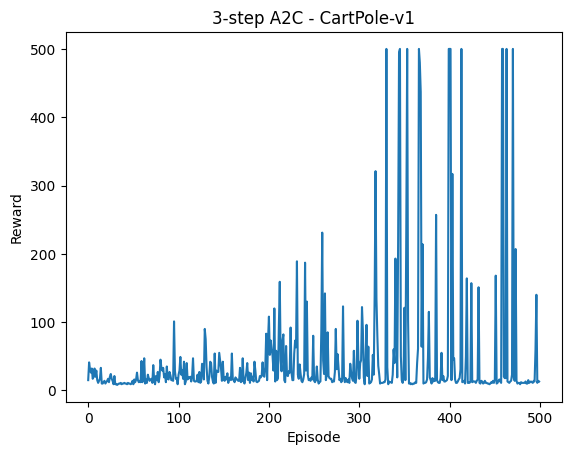

In [2]:
net = DiscreteActorCritic().to(DEVICE)
optimizer = torch.optim.Adam(net.parameters(), lr=0.001)
EPISODE = 500
seed = 2026
max_step = 500
future_rewards = 3
gamma = 0.99
value_coef = 0.5
entropy_coef = 0.010
dtype = torch.float32
device = next(net.parameters()).device
best_reward = float("-inf")
# 위 A2C 흐름을 환경 1개(N=1), rollout 길이 3(T=3)으로 실습
env = gym.make('CartPole-v1')
episode_rewards = []
best_net = None

try:
    for epi in range(1, EPISODE + 1):
        state, _ = env.reset(seed=seed + epi)
        logps, rewards, values, entropies = [], [], [], []
        episode_reward = 0.0

        for t in range(max_step):
            state_tensor = torch.as_tensor(state, dtype=dtype, device=device)
            logits, value = net(state_tensor)
            dist = Categorical(logits=logits)
            action = dist.sample()
            next_state, reward, term, trunc, _ = env.step(action.item())

            logps.append(dist.log_prob(action))
            rewards.append(reward)
            values.append(value)
            entropies.append(dist.entropy())
            episode_reward += reward
            done = term or trunc or t + 1 == max_step

            if len(rewards) % future_rewards == 0 or done:
                n_step = len(rewards) % future_rewards or future_rewards
                # 실제 종료는 미래 가치 0, 시간 제한은 마지막 관측의 가치로 부트스트랩
                with torch.no_grad():
                    if term:
                        running = torch.zeros((), dtype=dtype, device=device)
                    else:
                        next_tensor = torch.as_tensor(next_state, dtype=dtype, device=device)
                        _, running = net(next_tensor)
                    returns = []
                    for r in reversed(rewards[-n_step:]):
                        running = r + gamma * running
                        returns.append(running)
                    returns = torch.stack(returns[::-1])

                advantages = returns - torch.stack(values[-n_step:])
                actor_loss = -(torch.stack(logps[-n_step:]) * advantages.detach()).mean()
                critic_loss = advantages.pow(2).mean()
                entropy = torch.stack(entropies[-n_step:]).mean()
                loss = actor_loss + value_coef * critic_loss - entropy_coef * entropy

                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(net.parameters(), max_norm=0.5)
                optimizer.step()

            state = next_state
            if done:
                break

        episode_rewards.append(episode_reward)
        if epi == 1 or epi % 20 == 0:
            print(f'Episode {epi:3d} | reward: {episode_reward:.0f} | '
                  f'mean(last 20): {np.mean(episode_rewards[-20:]):.1f}')
        if episode_reward > best_reward:
            best_net = copy.deepcopy(net)
            best_reward = episode_reward
            print("\tbest_net saved - reward:", best_reward)
finally:
    env.close()

plt.plot(episode_rewards)
plt.xlabel('Episode')
plt.ylabel('Reward')
plt.title('3-step A2C - CartPole-v1')
plt.show()

In [3]:
def set_seed(seed=2026):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [4]:
def ac_n_step(reward_steps=3):
  net = DiscreteActorCritic().to(DEVICE)
  optimizer = torch.optim.Adam(net.parameters(), lr=0.001)
  EPISODE = 500
  seed = 2026
  set_seed(seed)
  max_step = 500
  future_rewards = reward_steps
  gamma = 0.99
  value_coef = 0.05
  entropy_coef = 0.010
  dtype = torch.float32
  device = next(net.parameters()).device
  best_reward = float("-inf")
  # 위 A2C 흐름을 환경 1개(N=1), rollout 길이 3(T=3)으로 실습
  env = gym.make('CartPole-v1')
  episode_rewards = []
  best_net = None

  try:
      for epi in range(1, EPISODE + 1):
          state, _ = env.reset(seed=seed + epi)
          logps, rewards, values, entropies = [], [], [], []
          episode_reward = 0.0

          for t in range(max_step):
              state_tensor = torch.as_tensor(state, dtype=dtype, device=device)
              logits, value = net(state_tensor)
              dist = Categorical(logits=logits)
              action = dist.sample()
              next_state, reward, term, trunc, _ = env.step(action.item())

              logps.append(dist.log_prob(action))
              rewards.append(reward)
              values.append(value)
              entropies.append(dist.entropy())
              episode_reward += reward
              done = term or trunc or t + 1 == max_step

              if len(rewards) % future_rewards == 0 or done:
                  n_step = len(rewards) % future_rewards or future_rewards
                  # 실제 종료는 미래 가치 0, 시간 제한은 마지막 관측의 가치로 부트스트랩
                  with torch.no_grad():
                      if term:
                          running = torch.zeros((), dtype=dtype, device=device)
                      else:
                          next_tensor = torch.as_tensor(next_state, dtype=dtype, device=device)
                          _, running = net(next_tensor)
                      returns = []
                      for r in reversed(rewards[-n_step:]):
                          running = r + gamma * running
                          returns.append(running)
                      returns = torch.stack(returns[::-1])

                  advantages = returns - torch.stack(values[-n_step:])
                  actor_loss = -(torch.stack(logps[-n_step:]) * advantages.detach()).mean()
                  critic_loss = advantages.pow(2).mean()
                  entropy = torch.stack(entropies[-n_step:]).mean()
                  loss = actor_loss + value_coef * critic_loss - entropy_coef * entropy

                  optimizer.zero_grad()
                  loss.backward()
                  torch.nn.utils.clip_grad_norm_(net.parameters(), max_norm=0.5)
                  optimizer.step()

              state = next_state
              if done:
                  break

          episode_rewards.append(episode_reward)
          if epi == 1 or epi % 100 == 0:
              print(f'Episode {epi:3d} | reward: {episode_reward:.0f} | '
                    f'mean(last 20): {np.mean(episode_rewards[-20:]):.1f}')
          if episode_reward > best_reward:
              best_net = copy.deepcopy(net)
              best_reward = episode_reward
              print("\tbest_net saved - reward:", best_reward)
  finally:
      env.close()

  plt.plot(episode_rewards)
  plt.xlabel('Episode')
  plt.ylabel('Reward')
  plt.title(f'3-step A2C - CartPole-v1 [n-step: {reward_steps}]')
  plt.show()

  return net, best_net

Episode   1 | reward: 15 | mean(last 20): 15.0
	best_net saved - reward: 15.0
Episode 100 | reward: 10 | mean(last 20): 9.2
Episode 200 | reward: 9 | mean(last 20): 9.5
Episode 300 | reward: 8 | mean(last 20): 9.3
Episode 400 | reward: 10 | mean(last 20): 9.4
Episode 500 | reward: 10 | mean(last 20): 9.3


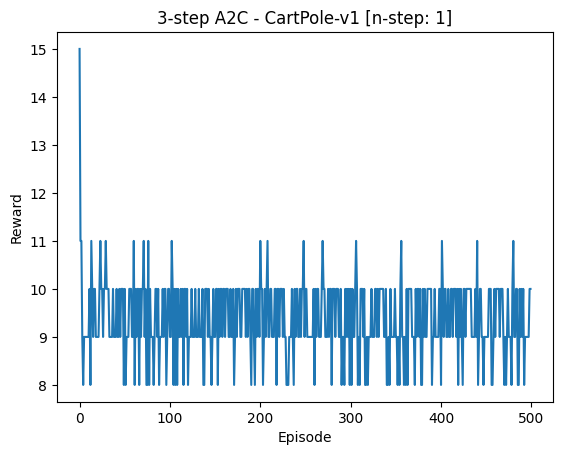

'\nEpisode   1 | reward: 15 | mean(last 20): 15.0\n\tbest_net saved - reward: 15.0\nEpisode 100 | reward: 10 | mean(last 20): 9.2\nEpisode 200 | reward: 9 | mean(last 20): 9.5\n\tbest_net saved - reward: 18.0\n\tbest_net saved - reward: 24.0\nEpisode 300 | reward: 8 | mean(last 20): 9.3\n\tbest_net saved - reward: 26.0\nEpisode 400 | reward: 10 | mean(last 20): 9.8\n\tbest_net saved - reward: 39.0\n\tbest_net saved - reward: 66.0\n\tbest_net saved - reward: 72.0\n\tbest_net saved - reward: 73.0\n\tbest_net saved - reward: 89.0\n\tbest_net saved - reward: 107.0\nEpisode 500 | reward: 46 | mean(last 20): 57.5\n'

In [5]:
ac_n_step(1)
"""
Episode   1 | reward: 15 | mean(last 20): 15.0
	best_net saved - reward: 15.0
Episode 100 | reward: 10 | mean(last 20): 9.2
Episode 200 | reward: 9 | mean(last 20): 9.5
	best_net saved - reward: 18.0
	best_net saved - reward: 24.0
Episode 300 | reward: 8 | mean(last 20): 9.3
	best_net saved - reward: 26.0
Episode 400 | reward: 10 | mean(last 20): 9.8
	best_net saved - reward: 39.0
	best_net saved - reward: 66.0
	best_net saved - reward: 72.0
	best_net saved - reward: 73.0
	best_net saved - reward: 89.0
	best_net saved - reward: 107.0
Episode 500 | reward: 46 | mean(last 20): 57.5
"""

Episode   1 | reward: 15 | mean(last 20): 15.0
	best_net saved - reward: 15.0
	best_net saved - reward: 22.0
	best_net saved - reward: 37.0
	best_net saved - reward: 38.0
	best_net saved - reward: 64.0
	best_net saved - reward: 65.0
	best_net saved - reward: 85.0
	best_net saved - reward: 105.0
	best_net saved - reward: 122.0
	best_net saved - reward: 135.0
	best_net saved - reward: 181.0
Episode 100 | reward: 29 | mean(last 20): 38.2
	best_net saved - reward: 190.0
Episode 200 | reward: 219 | mean(last 20): 110.9
	best_net saved - reward: 219.0
	best_net saved - reward: 383.0
	best_net saved - reward: 500.0
Episode 300 | reward: 13 | mean(last 20): 128.8
Episode 400 | reward: 21 | mean(last 20): 49.5
Episode 500 | reward: 15 | mean(last 20): 160.6


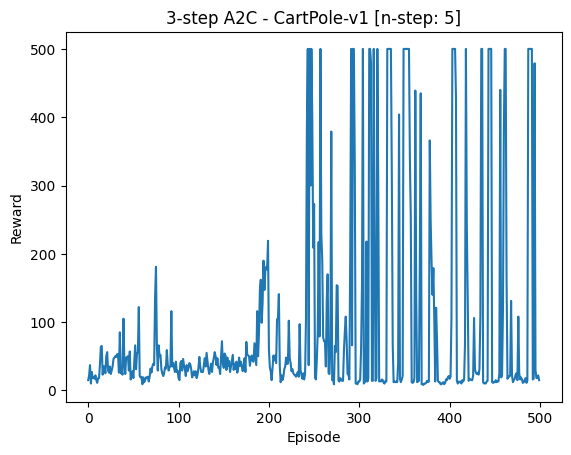

In [6]:
net, best_net = ac_n_step(5)

In [7]:
env = gym.make('CartPole-v1', render_mode="human")
state, _ = env.reset(seed=2)

rewards = []
step = 0

with torch.no_grad():
  while True:

    logits, _ = best_net(torch.tensor(state, dtype=dtype, device=device))
    action = int(logits.argmax(dim=-1).item())
    state, reward, term, trunc, _ = env.step(action)
    step += 1
    rewards.append(float(reward))
    if step % 25 == 0:
      print(step, "reward_mean:", np.mean(rewards))
    if term or trunc:
      print(
          "종료 스텝:", step,
          "최종 보상:", sum(rewards),
          "term:", term,
          "trunc:", trunc,
      )
      env.close()
      break

25 reward_mean: 1.0
50 reward_mean: 1.0
75 reward_mean: 1.0
100 reward_mean: 1.0
125 reward_mean: 1.0
150 reward_mean: 1.0
175 reward_mean: 1.0
200 reward_mean: 1.0
종료 스텝: 203 최종 보상: 203.0 term: True trunc: False


In [8]:
def make_envs(n=4, name="CartPole-v1", seed=2026):
    envs = [gym.make(name) for _ in range(n)]
    states = []
    for i, env in enumerate(envs):
        env.action_space.seed(seed + i)
        state, _ = env.reset(seed=seed + i)
        states.append(state)
    return envs, np.asanyarray(states, dtype=np.float32)

In [ ]:
# 4개의 게임을 각각 5스텝씩 실행하고, 총 20개의 경험을 모아 한 번 학습하는 과정을 300회 반복
# 300 * 4 * 5 = 6000(총 환경 스텝 수)
def train_a2c(updates=300, n_envs=4, rollout_steps=5, seed=2026, gamma=0.99, lr=7e-4, value_coef=0.5, entropy_coef=0.01, print_every=50):
    set_seed(seed)
    # envs = [환경0, 환경1, 환경2, 환경3]
    # states = [환경0의 현재 상태, 환경1의 현재 상태 ..]
    # 상태: 카트위치, 속도, 막대기 기울기, 각속도
    envs, states = make_envs(n_envs, seed=seed)
    model = DiscreteActorCritic().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    # 각 환경에서 현재 진행 중인 에피소드의 누적 보상을 저장
    episode_scores = np.zeros(n_envs, dtype=np.float64)
    completed = []
    history = []

    try:
        for update in range(1, updates + 1):
            # logps: 실제 선택한 행동의 로그 확률
            # vals: Critic이 예측한 현재 상태 가치
            # bootstraps: 다음 상태에서의 예상 가치
            # boundaries: 에피소드 종료 여부
            logps, vals, rewards, bootstraps = [], [], [], []
            boundaries, entropies = [], []

            for t in range(rollout_steps):
                x = torch.as_tensor(states, dtype=torch.float32, device=DEVICE)
                logits, value = model(x)
                dist = Categorical(logits=logits)
                actions = dist.sample()
                logps.append(dist.log_prob(actions))
                vals.append(value)
                entropies.append(dist.entropy())



                next_states, rs, bs, ends = [], [], [], []
                for i, env in enumerate(envs):
                    # ns: 다음상태
                    ns, r, terminated, truncated, _ = env.step(int(actions[i].item()))
                    episode_scores[i] += float(r)
                    # 두 종료 조건 중 하나라도 참이면 현재 에피소드가 끝났다고 판단
                    boundary = bool(terminated or truncated)
                    # rs: 즉시 보상
                    rs.append(float(r))
                    # ends: 에피소드 경계 여부
                    ends.append(boundary)
                    # bs: 종료 직전 다음 상태와 실제 종료 여부
                    # ns를 저장하는 이유는 truncated=True일 때 다음 상태 가치를 이용해 Bootstrap을 계산해야 하기 때문
                    bs.append((ns, bool(terminated)))
                    if boundary:
                        # 환경이 종료되었다면
                        # 1. 종료된 에피소드의 최종 보상을 저장
                        # 2. 해당 환경의 누적 보상을 0으로 초기화
                        # 3. env.reset()으로 새로운 에피소드를 시작
                        completed.append(float(episode_scores[i]))
                        episode_scores[i] = 0.0
                        ns, _ = env.reset()
                        # ns는 종료되지 않았다면 해동 후의 다음 상태, 종료되었다면 새로 초기화한 상태가 저장
                    next_states.append(ns)
                # Bootstrap
                # 아직 직접 경험하지 않은 미래의 보상을 Critic이 예측한 가치로 대신 계산하는 방법
                # 5스텝까지만 진행했지만 게임은 끝나지 않음 > 5스텝 이후에 받을 보상은 아직 알 수 없음
                # Critic이 다음 상태의 가치를 10점이라도 예측했다면, 그 값을 미래 보상의 추정치로 이용
                # bs: [(환경0의 다음 상태, False), (환경1의 다음 상태, True) ...]
                bootstrap_x = torch.as_tensor(
                    np.asanyarray([item[0] for item in bs], dtype=np.float32), device=DEVICE
                )
                with torch.no_grad():
                    _, bootstrap_values = model(bootstrap_x)
                    """
                    bootstrap_value = [12.0, 8.0, 15.0, 20.0]
                    terminated=True > 1
                    terminated=False > 0
                    환경 0, 다음 상태 가치 12.0, terminated False > 최종 Bootstrap 12
                    환경 1, 다음 상태 가치 8.0, terminated True > 최종 Bootstrap 0
                    ...
                    """
                    true_terminal = torch.tensor(
                        [float(item[1]) for item in bs], device=DEVICE
                    )
                    bootstrap_values = bootstrap_values * (1.0 - true_terminal)

                rewards.append(torch.tensor(rs, dtype=torch.float32, device=DEVICE))
                bootstraps.append(bootstrap_values)
                boundaries.append(torch.tensor(ends, dtype=torch.bool, device=DEVICE))
                states = np.asanyarray(next_states, dtype=np.float32)

            # 5스텝 동안 얻은 보상과 미래 예상 가치를 역순으로 합산
            # 마지막 스텝의 미래 가치를 먼저 알아야 이전 스탭의 Return을 계산할 수 있음
            """
                rewards = [1, 1, 1]
                gamma = 0.9
                next_value = 5

                역순 계산
                마지막 Bootstrap은 5
                t=2 > 1 + 0.9 * 5
                t=1 > 1 + 0.9 * 5.5
                t=0 > 1 + 0.9 * 5.95
            """
            running = bootstraps[-1]
            targets = [None] * rollout_steps
            for t in reversed(range(rollout_steps)):
                # 환경0이 세 번째 스텝에서 종료되고 네 번째 스텝부터 새로운 게임이 시작된다면
                # 이전 게임의 Return에 새로운 게임의 보상을 더하면 안됨
                # tensor[4]
                running = torch.where(boundaries[t], bootstraps[t], running)
                # tensor[4]
                running = rewards[t] + gamma * running
                # tensor[4]
                targets[t] = running

            target_t = torch.stack(targets).detach()
            value_t = torch.stack(vals)
            logp_t = torch.stack(logps)
            entropy_t = torch.stack(entropies)
            advantage = target_t - value_t

            actor_loss = -(logp_t * advantage.detach()).mean()
            critic_loss = advantage.square().mean()
            entropy_bonus = entropy_t.mean()
            loss = actor_loss + value_coef * critic_loss - entropy_coef * entropy_bonus

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 0.5)
            optimizer.step()

            recent = float(np.mean(completed[-20:])) if completed else np.nan
            history.append({'update': update, 'episodes_done': len(completed),
                            'recent20_reward': recent, 'loss': float(loss.item())})
            if update % print_every == 0:
                print(f'A2C update {update:4d}/{updates} | 종료 에피소드 {len(completed):4d} '
                      f'| 최근20 평균 {recent:7.2f}')

    finally:
        for env in envs:
            env.close()
    return model, pd.DataFrame(history), completed

In [10]:
a2c_model, a2c_hist, a2c_scores = train_a2c(
    updates=600, n_envs=4, rollout_steps=5, seed=2026,
    print_every=50
)

A2C update   50/600 | 종료 에피소드   34 | 최근20 평균   28.30
A2C update  100/600 | 종료 에피소드   69 | 최근20 평균   27.95
A2C update  150/600 | 종료 에피소드  115 | 최근20 평균   17.60
A2C update  200/600 | 종료 에피소드  152 | 최근20 평균   24.60
A2C update  250/600 | 종료 에피소드  177 | 최근20 평균   37.90
A2C update  300/600 | 종료 에피소드  210 | 최근20 평균   35.30
A2C update  350/600 | 종료 에피소드  234 | 최근20 평균   40.85
A2C update  400/600 | 종료 에피소드  256 | 최근20 평균   42.20
A2C update  450/600 | 종료 에피소드  280 | 최근20 평균   44.85
A2C update  500/600 | 종료 에피소드  298 | 최근20 평균   52.25
A2C update  550/600 | 종료 에피소드  322 | 최근20 평균   40.95
A2C update  600/600 | 종료 에피소드  342 | 최근20 평균   54.25


In [11]:
a2c_hist

,update,episodes_done,recent20_reward,loss
0,1,0,NaN,7.313445
1,2,0,NaN,7.354511
2,3,2,13.50,5.171424
3,4,2,13.50,7.260337
4,5,2,13.50,7.152939
...,...,...,...,...
595,596,339,54.75,52.520317
596,597,341,55.95,148.860214
597,598,341,55.95,3.857908
598,599,341,55.95,3.582532


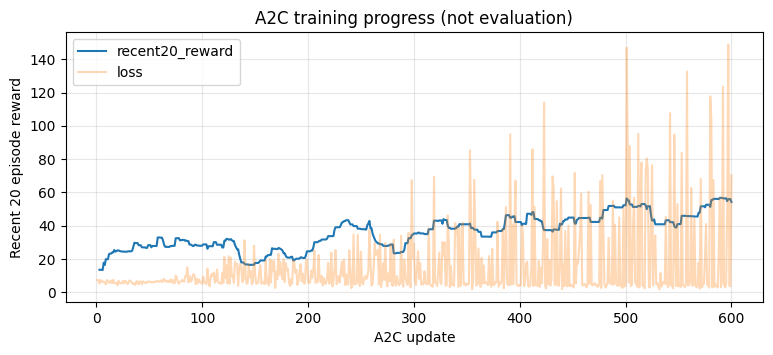

In [15]:
plt.figure(figsize=(9, 3.5))
plt.plot(a2c_hist['update'], a2c_hist['recent20_reward'], label="recent20_reward")
plt.plot(a2c_hist['update'], a2c_hist['loss'], label="loss", alpha=0.3)
plt.xlabel('A2C update')
plt.legend()
plt.ylabel('Recent 20 episode reward')
plt.title('A2C training progress (not evaluation)')
plt.grid(alpha=0.3)
plt.show()